Jagmeet Singh
Data Mining 2026
Assignment 1

https://github.com/singhj95/DataMiningI

#1. Feature Extraction: Edge Histogram and Similarity Measurements

## Importing the Data

In [1]:
import matplotlib.pyplot as plt
import skimage as ski
from skimage import data, exposure
from skimage.color import rgb2gray
from skimage import filters
from skimage.feature import hog
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import pairwise_kernels
import seaborn as sns

dark = ski.io.imread("/content/drive/MyDrive/Colab Notebooks/DataMining/content/train/Dark/dark (1).png")
green = ski.io.imread("/content/drive/MyDrive/Colab Notebooks/DataMining/content/train/Green/green (1).png")
light = ski.io.imread("/content/drive/MyDrive/Colab Notebooks/DataMining/content/train/Light/light (1).png")
medium = ski.io.imread("/content/drive/MyDrive/Colab Notebooks/DataMining/content/train/Medium/medium (1).png")

original_beans = [dark, green, light, medium]
grayscale_beans = []
sobel_beans = []
hist_beans = []
hist_beans_centers = []

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DataMining/content/Coffee Bean.csv')
beans_training = df[df['data set'] == 'train']
beans_testing = df[df['data set'] == 'test']
training_sobel = []
training_hist = []
training_hist_centers = []
bean_classes = beans_training['labels'].unique()


def angle(dx, dy):
#Calculate the angles between horizontal and vertical operators.
  return np.mod(np.arctan2(dy, dx), np.pi)

def bean_sobel(bean):
  return angle(filters.sobel_h(bean), filters.sobel_v(bean))

def bean_histogram(bean):
  return exposure.histogram(bean, 36)


## Grayscaling the Images

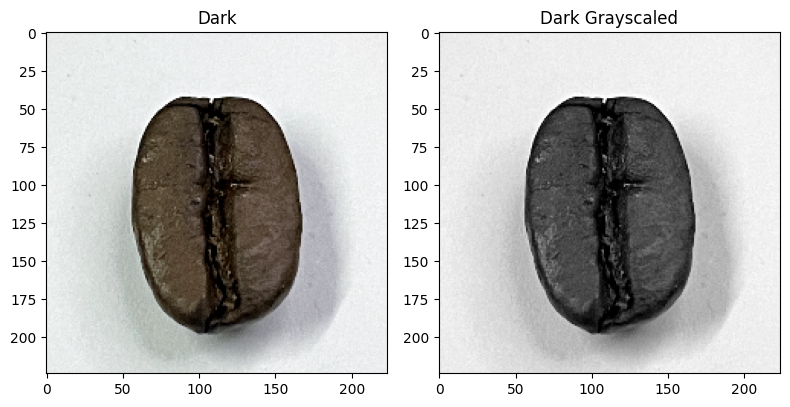

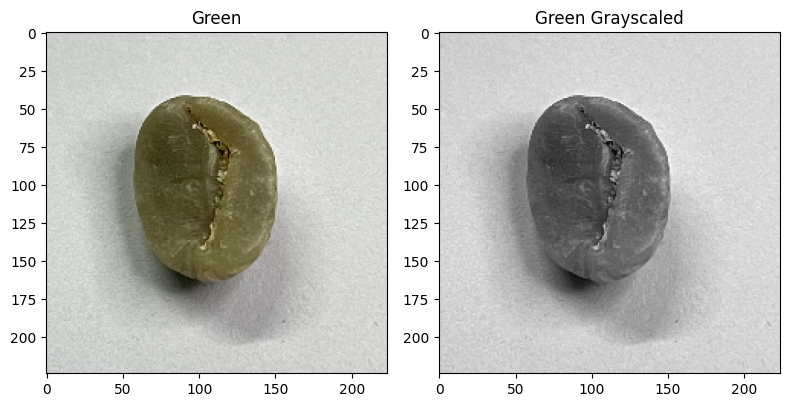

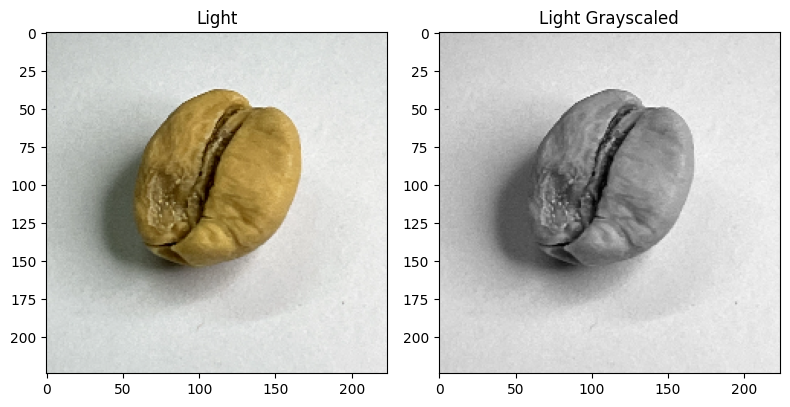

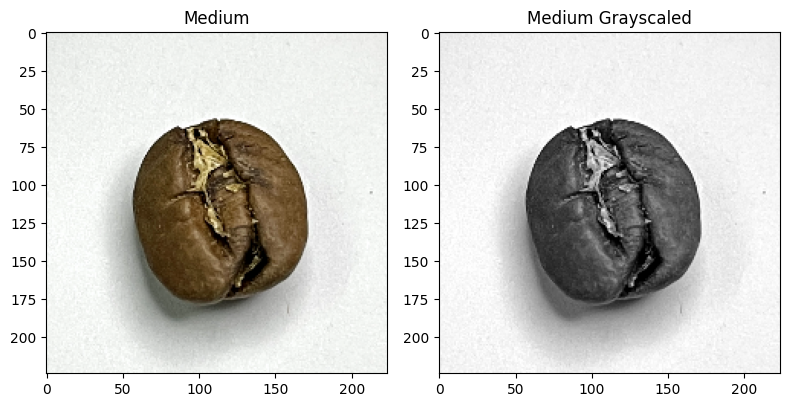

In [2]:
for idx, bean in enumerate(original_beans):
  grayscale_bean = rgb2gray(bean)
  grayscale_beans.append(grayscale_bean)
  fig, axes = plt.subplots(1, 2, figsize=(8, 4))
  ax = axes.ravel()

  ax[0].imshow(bean)
  ax[0].set_title(bean_classes[idx])
  ax[1].imshow(grayscale_bean, cmap=plt.cm.gray)
  ax[1].set_title(bean_classes[idx] + " Grayscaled")
  fig.tight_layout()
  plt.show()

## Sobel Representation

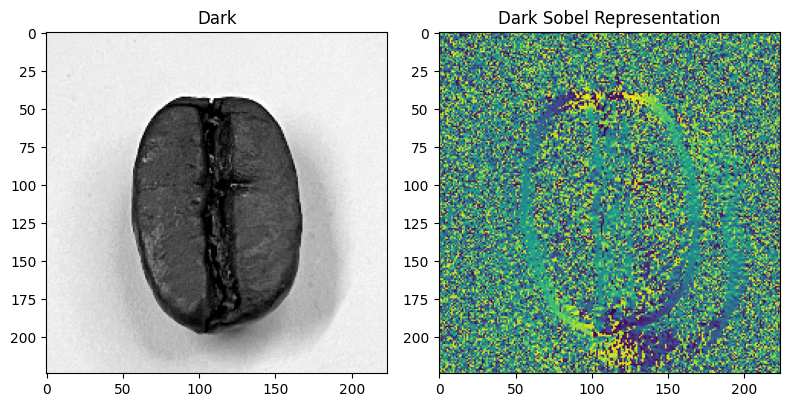

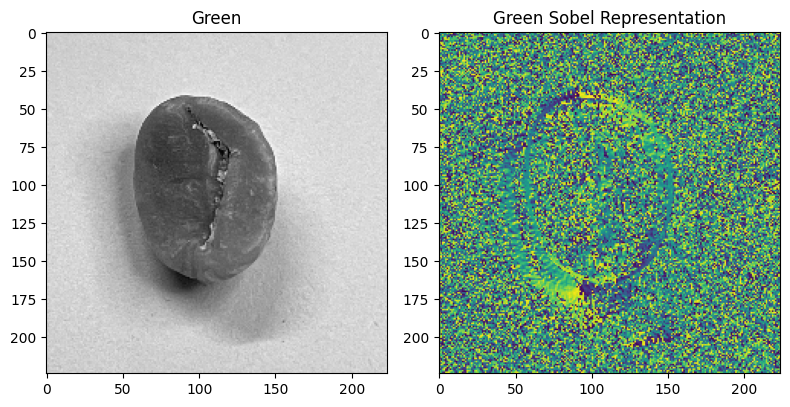

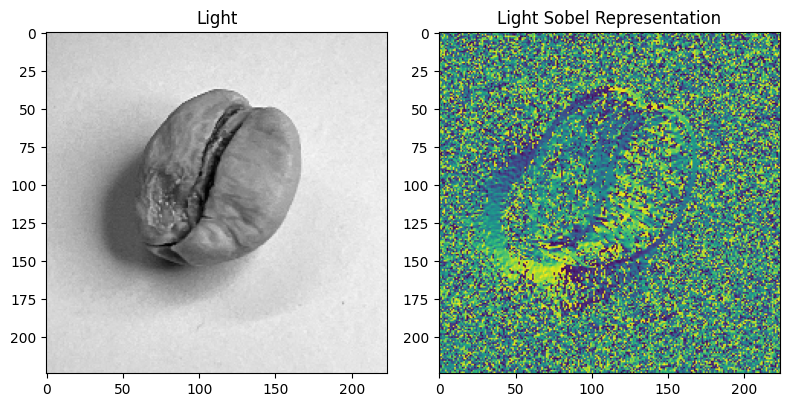

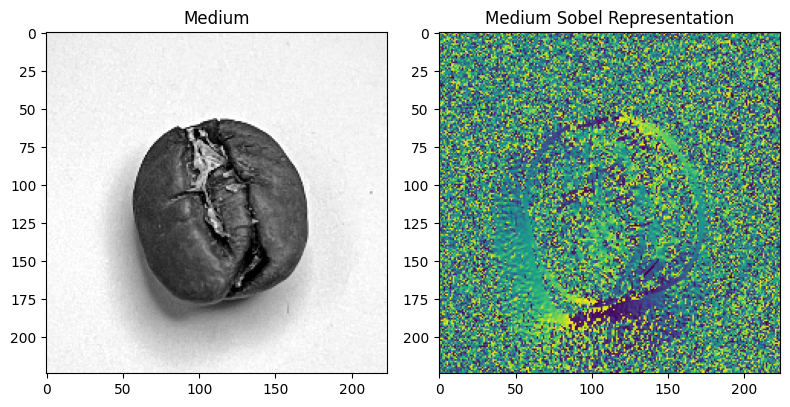

In [3]:
for idx, bean in enumerate(grayscale_beans):
  sobel_bean = bean_sobel(bean)
  sobel_beans.append(sobel_bean)

  fig, axes = plt.subplots(1, 2, figsize=(8, 4))
  ax = axes.ravel()

  ax[0].imshow(bean, cmap=plt.cm.gray)
  ax[0].set_title(bean_classes[idx])
  ax[1].imshow(sobel_bean)
  ax[1].set_title(bean_classes[idx] + " Sobel Representation")
  fig.tight_layout()
  plt.show()

## Histograms

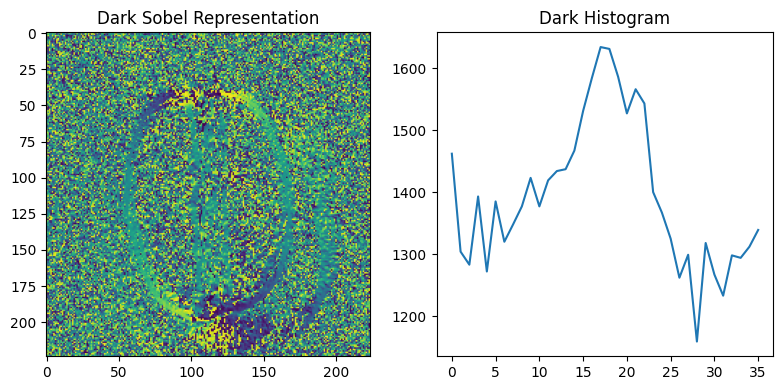

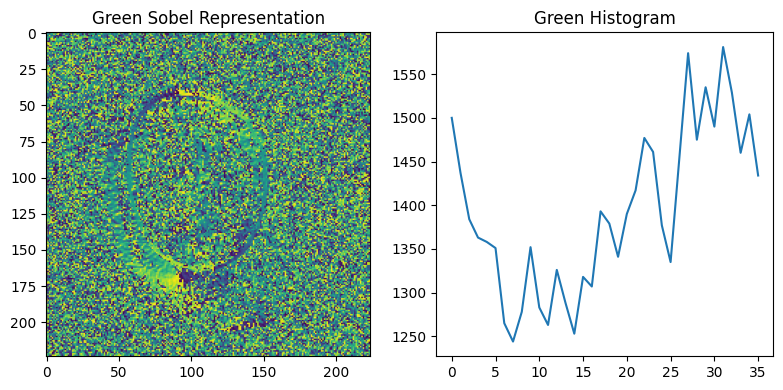

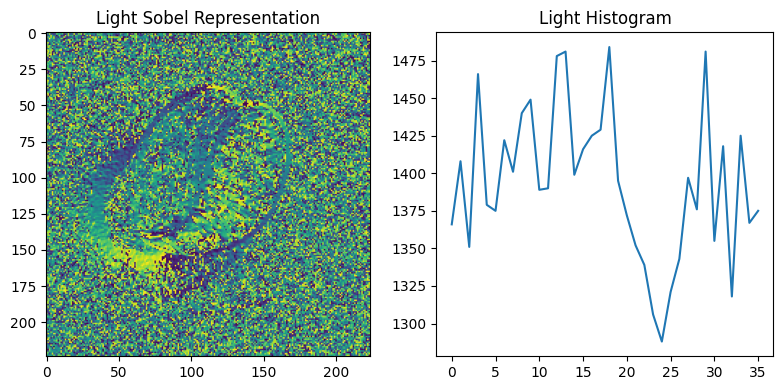

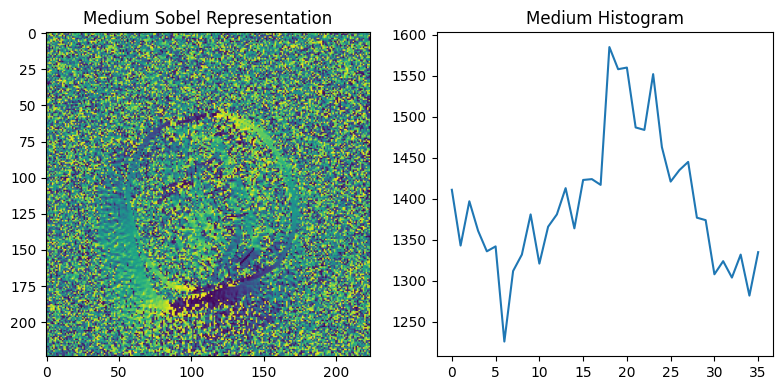

In [4]:
for idx, bean in enumerate(sobel_beans):
  hist_bean, hist_bean_center = bean_histogram(bean)
  hist_beans.append(hist_bean)
  hist_beans_centers.append(hist_bean_center)

  fig, axes = plt.subplots(1, 2, figsize=(8, 4))
  ax = axes.ravel()

  ax[0].imshow(bean)
  ax[0].set_title(bean_classes[idx] + " Sobel Representation")
  ax[1].plot(hist_bean)
  ax[1].set_title(bean_classes[idx] + " Histogram")
  fig.tight_layout()
  plt.show()

## Pairwise Distances

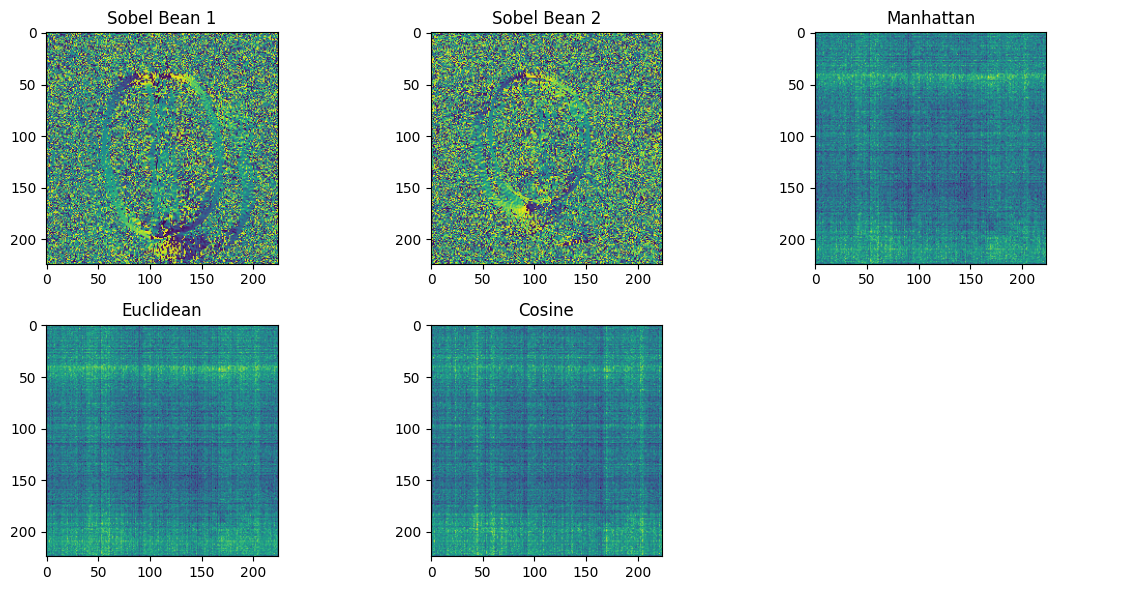

In [5]:
manhattan = pairwise_distances(sobel_beans[0], sobel_beans[1], metric = 'manhattan')
euclidean = pairwise_distances(sobel_beans[0], sobel_beans[1], metric = 'euclidean')
cosine = pairwise_distances(sobel_beans[0], sobel_beans[1], metric = 'cosine')

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
ax = axes.ravel()
ax[0].imshow(sobel_beans[0])
ax[0].set_title("Sobel Bean 1")
ax[1].imshow(sobel_beans[1])
ax[1].set_title("Sobel Bean 2")
ax[2].imshow(manhattan)
ax[2].set_title("Manhattan")
ax[3].imshow(euclidean)
ax[3].set_title('Euclidean')
ax[4].imshow(cosine)
ax[4].set_title('Cosine')
ax[5].axis('off')
fig.tight_layout()
plt.show()

# 2. Histogram of Oriented Gradients

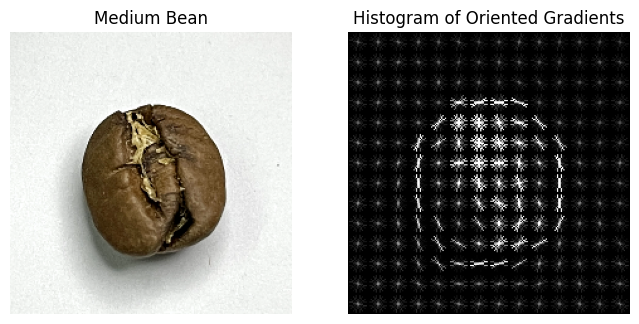

In [6]:
image = original_beans[3]

fd, hog_image = hog(
    image,
    orientations=8,
    pixels_per_cell=(16, 16),
    cells_per_block=(1, 1),
    visualize=True,
    channel_axis=-1,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Medium Bean')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')
plt.show()

# 4. Principal Component Analysis

In [7]:
for index, row in beans_training.iterrows():
  bean = ski.io.imread('/content/drive/MyDrive/Colab Notebooks/DataMining/content/' + row['filepaths'])
  bean = rgb2gray(bean)
  sobel_bean = bean_sobel(bean)
  training_sobel.append(sobel_bean)
  histogram_bean, histogram_bean_center = bean_histogram(sobel_bean)
  training_hist.append(histogram_bean)
  training_hist_centers.append(hist_bean_center)
  histograms = np.array(training_hist)

In [8]:
pca = PCA(n_components=2).fit_transform(training_hist)

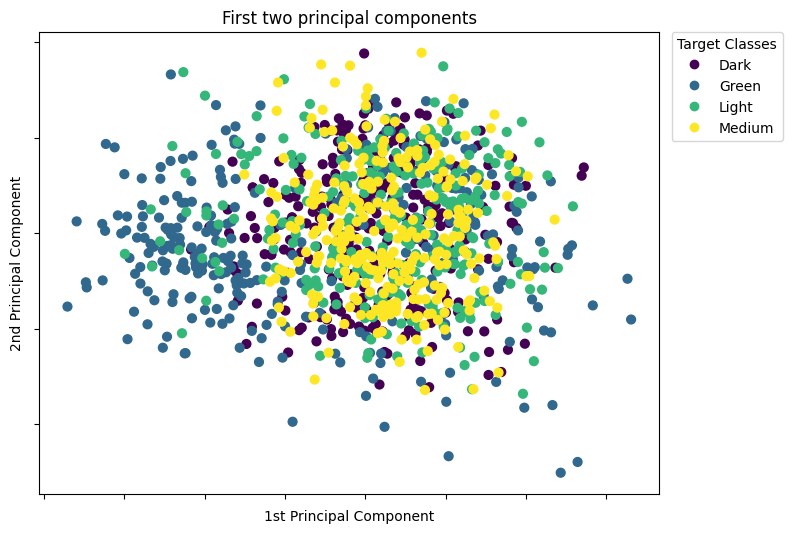

In [9]:
fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot()
scatter = ax.scatter(
    pca[:, 0],
    pca[:, 1],
    c=beans_training['class index'],
    cmap='viridis',
    s=40,
)

ax.set(
    title="First two principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component",
)

handles, _ = scatter.legend_elements()

ax.legend(
    handles = handles,
    labels=list(bean_classes),
    title="Target Classes",
    loc="upper left",          # Places the legend box
    bbox_to_anchor=(1.02, 1),   # Shifts the legend completely outside the chart box so it doesn't cover data
    borderaxespad=0
)

ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])

plt.show()

All of the classes overlap, but the Green and Light beans are a lot more spread out. Dark and Medium are more contained. This makes sense as the images are grayscaled. All beans look similar to each other, but the Green and Light beans are lighter compared to the Dark and Medium beans.

## Text Dataset

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline


text_dataset = pd.read_json('/content/drive/MyDrive/Colab Notebooks/DataMining/Assignment 1/train.json', lines = 'true')

selected_features = ['pessimism', 'surprise', 'love', 'anger']

df_filtered = text_dataset[text_dataset[selected_features].any(axis=1)].copy()

print(f"Original tweets: {len(text_dataset)}")
print(f"Tweets matching 4 chosen classes: {len(df_filtered)}")

tweets = df_filtered['Tweet'].astype(str)

count_vectorizer = CountVectorizer()
count_matrix = count_vectorizer.fit_transform(tweets)
print(f"Count Vectorizer Shape: {count_matrix.shape}")

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(tweets)
print(f"TF-IDF Vectorizer Shape: {tfidf_matrix.shape}")

count_svd = PCA(n_components=2)
count_reduced_tweets = count_svd.fit_transform(count_matrix)

tfidf_svd = PCA(n_components=2)
tfidf_reduced_tweets = tfidf_svd.fit_transform(tfidf_matrix)

count_df_plot = pd.DataFrame(count_reduced_tweets, columns=['Component_1', 'Component_2'])
tfidf_df_plot = pd.DataFrame(tfidf_reduced_tweets, columns=['Component_1', 'Component_2'])

def get_feature(row):
    for feature in selected_features:
        if row[feature] == True:
            return feature
    return 'None'

count_df_plot['Feature'] = df_filtered.apply(get_feature, axis=1).values
tfidf_df_plot['Feature'] = df_filtered.apply(get_feature, axis=1).values

Original tweets: 3000
Tweets matching 4 chosen classes: 1763
Count Vectorizer Shape: (1763, 6673)
TF-IDF Vectorizer Shape: (1763, 6673)


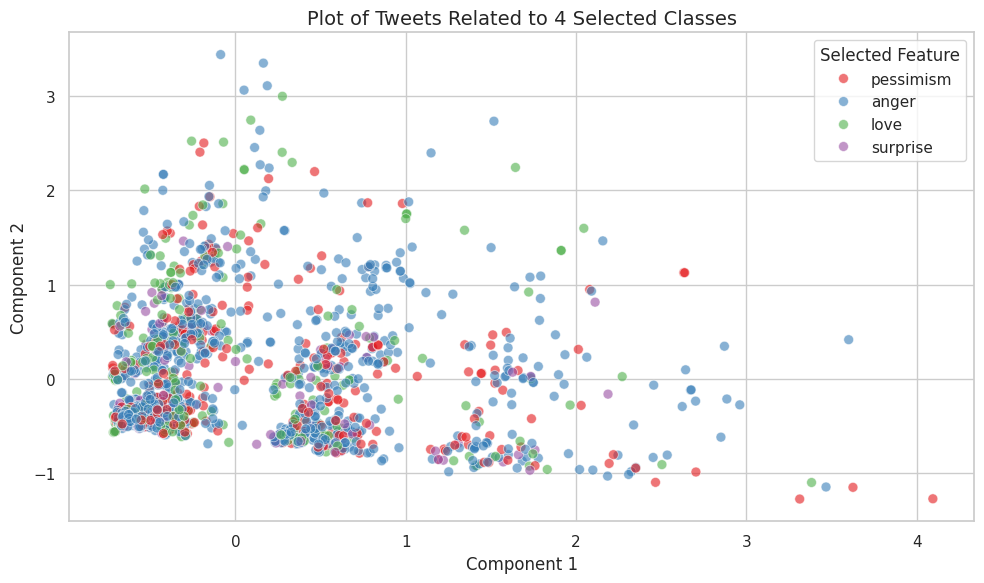

In [11]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    x='Component_1',
    y='Component_2',
    hue='Feature',
    data=count_df_plot,
    palette="Set1",
    s=50,
    alpha=0.6
)

plt.title("Plot of Tweets Related to 4 Selected Classes", fontsize=14)
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(title="Selected Feature")
plt.tight_layout()
plt.show()

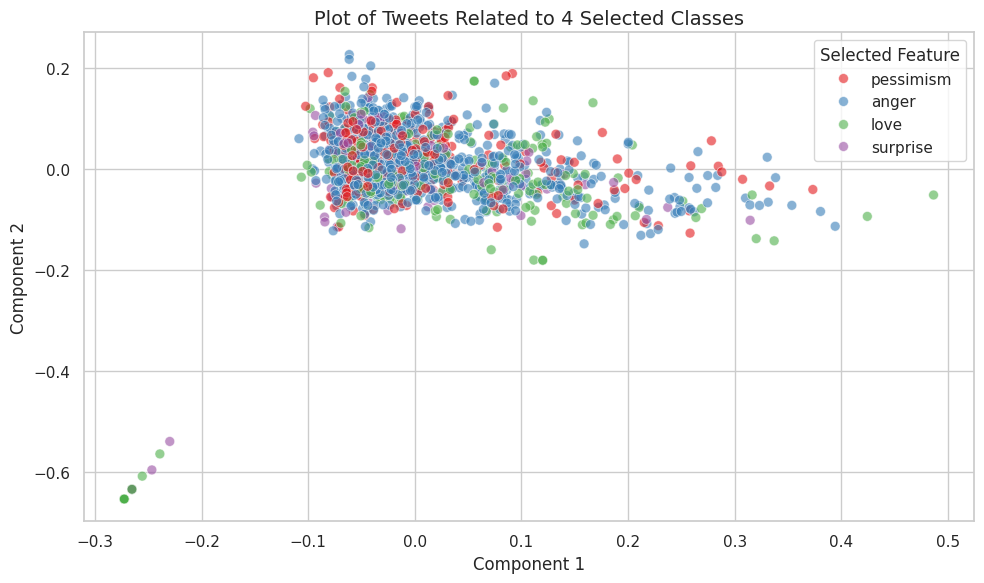

In [12]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    x='Component_1',
    y='Component_2',
    hue='Feature',
    data=tfidf_df_plot,
    palette="Set1",
    s=50,
    alpha=0.6
)

plt.title("Plot of Tweets Related to 4 Selected Classes", fontsize=14)
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(title="Selected Feature")
plt.tight_layout()
plt.show()

 There are no classes which are separable. They are scattered in an interesting way in the count vectorizer plot, almost with separate bins like a histogram. Across Component 1, and down Component 2, the scatter fades out.
 The TFIDF has every class grouped pretty similarly, but with a few outliers that change the shape of the plot.